# Mock datasets
Ben Pennell, MPIA

February 20th, 2026
_____


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

/home/bepennell/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
from GaiamockWrapper import SimulateAstrometry, style, utils
from GaiamockWrapper.SimulateAstrometry import simulate_population_astrometry as simpopast

parent_table = Table.read("./data/solar_mass_primaries.fits", format="fits")

# Propagating through the DR3 pipeline

## a simple example

In [8]:
objs, astrometry_results = simpopast(object_count=5000, catalogue=parent_table, binary_fraction=0.5,
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, 
                                        return_fits=True, return_statistics=True, n_jobs=5)

(1) Assigning companions to 2500 sources...
(2) Computing astrometry for 5000 sources...


Computing astrometry for all sources...:   0%|          | 0/5000 [00:00<?, ?it/s]

In [12]:
utils.postproces_solution_type(objs, astrometry_results)
processed_res = utils.postprocess_fits(astrometry_results)

/home/bepennell/.local/lib/python3.10/site-packages/numpy/_core/numeric.py:353: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(a, fill_value, casting='unsafe')


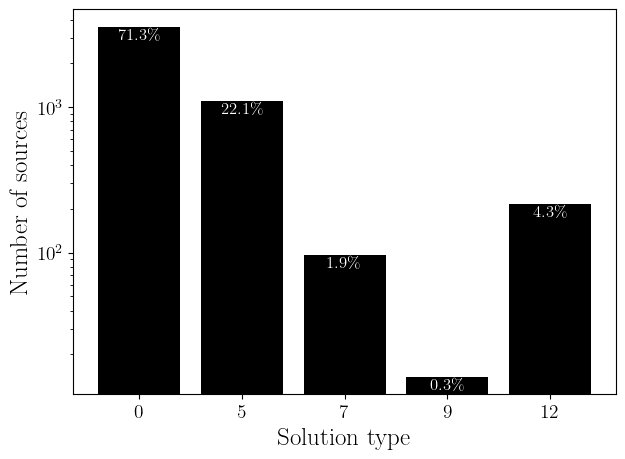

In [16]:
soltypes = [0,5,7,9,12]
counts, bins, _ = plt.hist(np.digitize(objs["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
plt.xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
plt.xlabel("Solution type")
plt.ylabel("Number of sources")
plt.yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        plt.text(i, count * 0.78, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

plt.show()

## Changing the distances of the parent sample
the sample stars spaced out between 50 and 200pc, and we can just decide to readjust to, say, 200-500pc

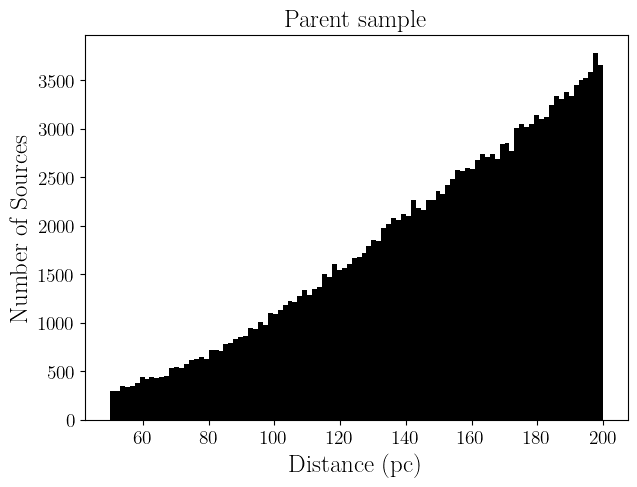

In [4]:
plt.hist(1000/parent_table["parallax"], bins=100)
plt.xlabel("Distance (pc)")
plt.ylabel("Number of Sources")
plt.title("Parent sample")
plt.show()

In [5]:
objs, astrometry_results = simpopast(object_count=2500, catalogue=parent_table, binary_fraction=0.5,
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, 
                                        reassign_parallaxes=True, plx_kwargs={"dist_range": (200, 500)},
                                        return_fits=True, return_statistics=True, n_jobs=5)

(1) Assigning companions to 1250 sources...
(2) Computing astrometry for 2500 sources...


Computing astrometry for all sources...:   0%|          | 0/2500 [00:00<?, ?it/s]

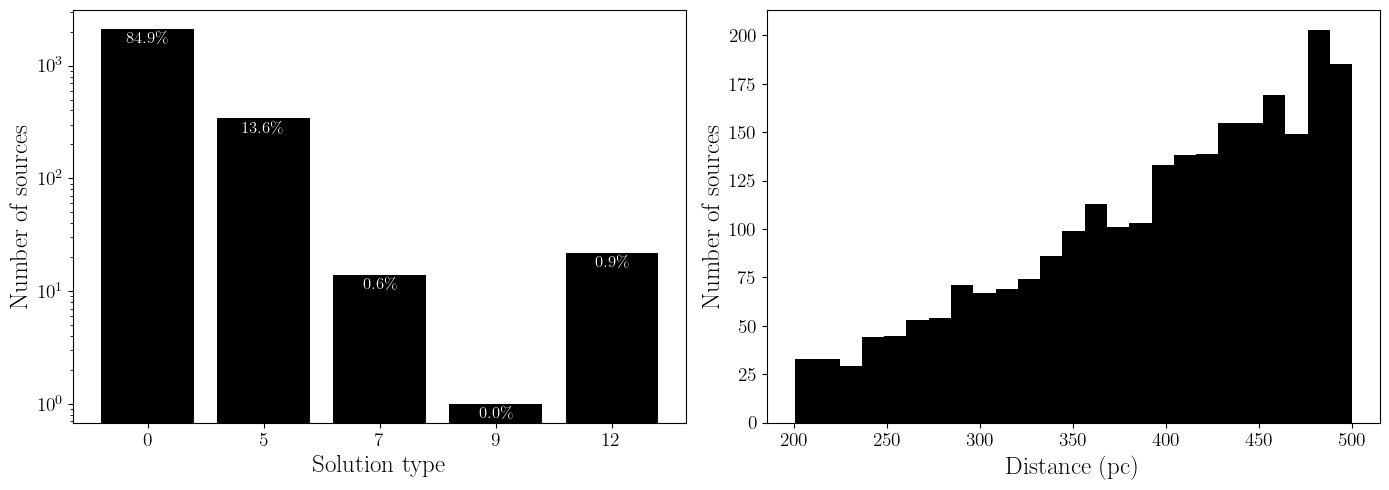

In [9]:
fig, axs = plt.subplots(1,2, figsize=(14,5))

ax = axs[0]
soltypes = [0,5,7,9,12]
utils.postproces_solution_type(objs, astrometry_results)
counts, bins, _ = ax.hist(np.digitize(objs["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
ax.set_xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
ax.set_xlabel("Solution type")
ax.set_ylabel("Number of sources")
ax.set_yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        ax.text(i, count * 0.7, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

ax = axs[1]
ax.hist(1000/objs["parallax"], bins=25)
ax.set_xlabel("Distance (pc)")
ax.set_ylabel("Number of sources")

plt.tight_layout()
plt.show()

and we can see that the higher order solutions become less common, as we expect.

## Sampling on companion mass instead

In [10]:
objs, astrometry_results = simpopast(object_count=5000, catalogue=parent_table, binary_fraction=0.5,
                                        astrometry_function=SimulateAstrometry.gw.dr3_astrometric_pipeline, 
                                        companion_mass_model=utils.uniform_distribution, m_kwargs={"lims": [0.2, 0.65]}, # let's make the companions just m stars :)
                                        compute_mass_ratios=False,
                                        return_fits=True, return_statistics=True, n_jobs=5)

(1) Assigning companions to 2500 sources...
(2) Computing astrometry for 5000 sources...


Computing astrometry for all sources...:   0%|          | 0/5000 [00:00<?, ?it/s]

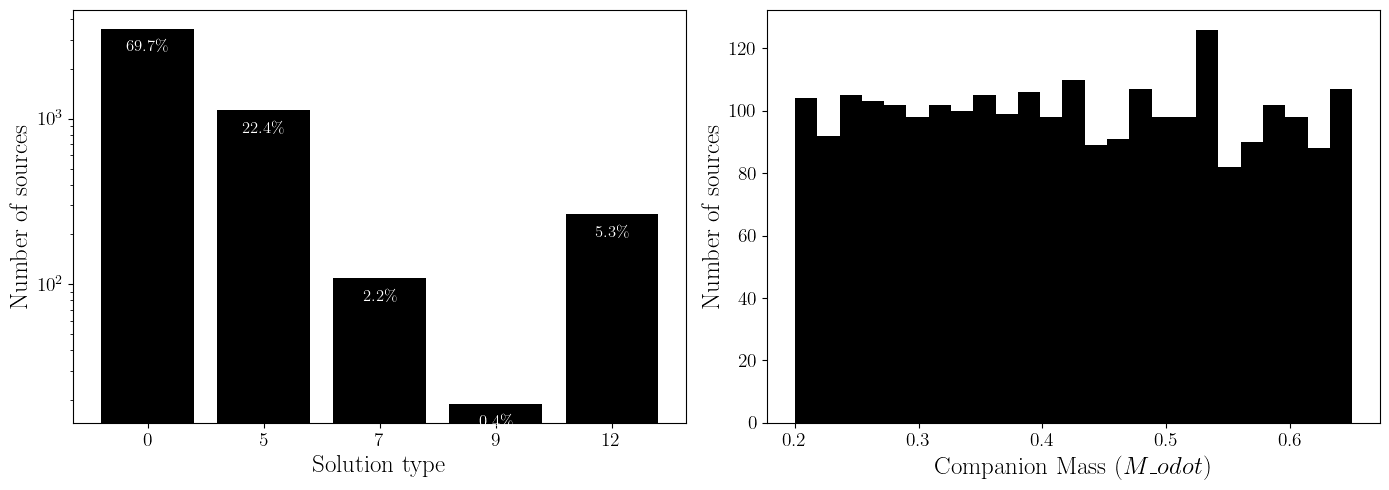

In [11]:
fig, axs = plt.subplots(1,2, figsize=(14,5))

ax = axs[0]
soltypes = [0,5,7,9,12]
utils.postproces_solution_type(objs, astrometry_results)
counts, bins, _ = ax.hist(np.digitize(objs["solution_type"], soltypes, right=True), bins=np.arange(len(soltypes)+1)-0.5, rwidth=0.8)
ax.set_xticks(ticks=np.arange(len(soltypes)), labels=soltypes)
ax.set_xlabel("Solution type")
ax.set_ylabel("Number of sources")
ax.set_yscale("log")

rates = counts / counts.sum() * 100
for i, (count, rate) in enumerate(zip(counts, rates)):
    if count > 0:
        ax.text(i, count * 0.7, f"{rate:.1f}\%", c="white", fontsize=12, ha="center", va="bottom")

ax = axs[1]
ax.hist(objs["m2"], bins=25)
ax.set_xlabel(r"Companion Mass ($M\_odot$)")
ax.set_ylabel("Number of sources")

plt.tight_layout()
plt.show()